# Numerical Methods for Finance - MMF2021

# Project 1 - Pairs Trading

# Author: Jaime Corzo Galdó

The trade is long $100,000 of Pepsi (PEP) and short $100,000 of Coca-Cola (KO). The original $100,000 cash remains in the bank and earns 5% per year.

The objective is to simulate the trade over 60 trading days and compare different assumptions for the behavior of KO, PEP, and their spread.

In [165]:
%pip install -q yfinance

Note: you may need to restart the kernel to use updated packages.


### Date convention

The project statement mentions October 12th as the trade date, but the specific valuation question asks to enter on October 9th and value the position on October 16th.

I therefore use October 9th, 2026 as the entry date throughout the analysis so that the simulation is consistent with the question being answered.

Note: Adjusted prices are used to estimate historical returns and the random-walk parameters. Regular closing prices are used for the relative-value trading signal and for reporting actual entry and exit price levels.

In [166]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

rng = np.random.default_rng(42)

tickers = ["KO", "PEP"]

entry_date = "2026-10-09"
valuation_date = "2026-10-16"

initial_cash = 100_000
position_size = 100_000
cash_rate = 0.05

n_days = 60
n_paths = 1_000_000

## 1. Historical data

I download daily KO and PEP prices from Yahoo Finance. I keep both the regular close and the adjusted close.

Adjusted prices account for dividends and stock splits, so I use them to calculate historical returns. The data are aligned by date so that both stocks use the same trading days.

I download a relatively long history first. The calibration window will be chosen later after checking how stable the estimated parameters are.

In [167]:
download_start = "2010-01-01"

data_end = (
    pd.Timestamp(entry_date) + pd.Timedelta(days=1)
).strftime("%Y-%m-%d")

raw = yf.download(
    tickers,
    start=download_start,
    end=data_end,
    auto_adjust=False,
    progress=False
)

close = raw["Close"][tickers].dropna()
adj_close = raw["Adj Close"][tickers].dropna()

print("First date:", adj_close.index[0].date())
print("Last date:", adj_close.index[-1].date())
print("Observations:", len(adj_close))

display(adj_close.tail())

First date: 2010-01-04
Last date: 2026-10-09
Observations: 4218


Ticker,KO,PEP
Date,,
2026-10-05,86.510002,125.650002
2026-10-06,86.169998,125.709999
2026-10-07,85.820000,123.730003
2026-10-08,87.769997,128.339996
2026-10-09,88.050003,125.970001


### Daily returns

I calculate daily log returns from adjusted prices:

$$
r_t = \log\left(\frac{P_t}{P_{t-1}}\right).
$$

Using adjusted prices avoids treating dividend payments as negative stock returns.

In [168]:
daily_returns = np.log(adj_close / adj_close.shift(1)).dropna()

summary = daily_returns.agg(["mean", "std", "min", "max"])
display(summary.round(5))

print("\nCorrelation:")
display(daily_returns.corr().round(3))

Ticker,KO,PEP
mean,0.00039,0.00029
std,0.01085,0.01123
min,-0.10173,-0.12136
max,0.06278,0.12166



Correlation:


Ticker,KO,PEP
Ticker,,
KO,1.000,0.691
PEP,0.691,1.000


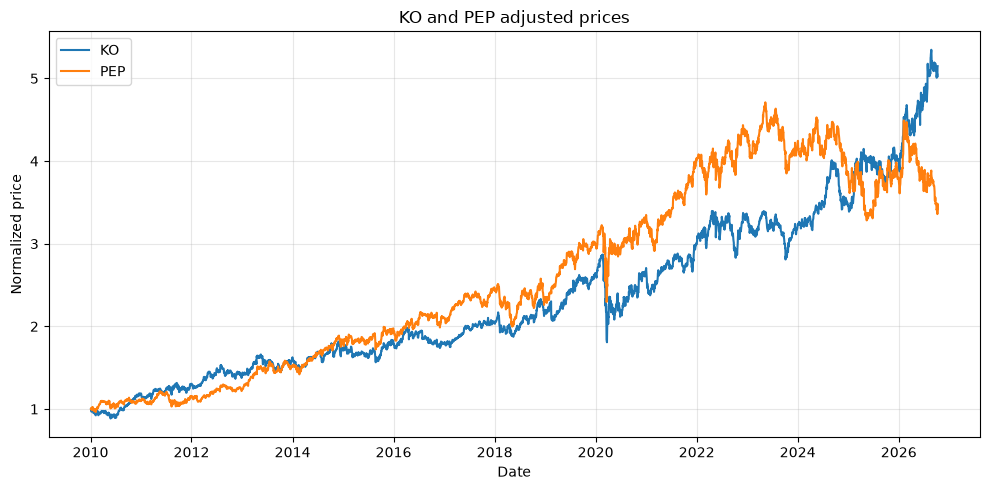

In [169]:
# We divide the adjusted close prices by the value of the first day,
# this way both actions start at a price of 1, so we can compare how two stocks,
# which shares have different prices, grow over time.
#
# It answers the question: If I had invested $1 in each one at the beginning, what the evolution would be?
normalized = adj_close / adj_close.iloc[0] 

plt.figure(figsize=(10, 5))

plt.plot(normalized.index, normalized["KO"], label="KO")
plt.plot(normalized.index, normalized["PEP"], label="PEP")

plt.title("KO and PEP adjusted prices")
plt.ylabel("Normalized price")
plt.xlabel("Date")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The normalized prices show that KO and PEP have shared broad movements over time, but the distance between them is not constant. This suggests that correlation in returns and stability of the relative price should be studied separately.

## 2. Sensitivity to the calibration window

Parameter estimates can depend on the amount of historical data used. A longer window provides more observations, while a shorter window gives more weight to recent market behavior.

I use 5 years as the baseline calibration window. I also calculate the same parameters using 2 and 10 years of pre-entry data to check how sensitive the estimates are to this assumption.

### Estimating the model parameters

For each historical window, I estimate the average daily log return, daily volatility, and the correlation between KO and PEP.

Since log returns are additive over time, I annualize the average daily return by multiplying by 252. Volatility is annualized using the square-root-of-time rule:

$$
\mu_{annual} = 252\mu_{daily},
\qquad
\sigma_{annual} = \sqrt{252}\sigma_{daily}.
$$

The volatility scaling assumes that daily return shocks have approximately constant variance and little serial dependence. This is a simplification, since volatility can change over time and cluster during turbulent periods.

Correlation measures the relationship between KO and PEP returns on the same day. Later, the correlated random walk will allow this cross-sectional dependence while keeping shocks independent across different days.

Only observations strictly before the entry date are used for calibration. The entry-date close is used only as the starting price of the trade.

In [170]:
entry = pd.Timestamp(entry_date)

baseline_years = 5
sensitivity_windows = [2, 5, 10]

window_results = []

for years in sensitivity_windows:
    start = entry - pd.DateOffset(years=years)

    # Use only information available before the entry date
    r = daily_returns[
        (daily_returns.index >= start) &
        (daily_returns.index < entry)
    ]

    window_results.append({
        "Window": f"{years} years",
        "Observations": len(r),
        "KO drift (%)": r["KO"].mean() * 252 * 100,
        "PEP drift (%)": r["PEP"].mean() * 252 * 100,
        "KO volatility (%)": r["KO"].std() * np.sqrt(252) * 100,
        "PEP volatility (%)": r["PEP"].std() * np.sqrt(252) * 100,
        "Correlation": r["KO"].corr(r["PEP"])
    })

window_summary = pd.DataFrame(window_results).set_index("Window")
display(window_summary.round(2))


,Observations,KO drift (%),PEP drift (%),KO volatility (%),PEP volatility (%),Correlation
Window,,,,,,
2 years,501,14.78,-10.36,17.92,21.61,0.60
5 years,1254,12.66,-0.67,16.69,18.99,0.68
10 years,2513,10.56,5.03,18.49,19.98,0.71


The 5-year window is my baseline calibration period. The 2-year and 10-year estimates are only used to check how sensitive the parameters are to this choice.

The baseline window is fixed before comparing the simulations with the realized post-entry outcome. This avoids choosing the historical window simply because it happens to fit what occurred afterwards (avoiding data snooping).


In [171]:
baseline_start = entry - pd.DateOffset(years=baseline_years)

baseline_returns = daily_returns[
    (daily_returns.index >= baseline_start) &
    (daily_returns.index < entry)
]

baseline_prices = adj_close[
    (adj_close.index >= baseline_start) &
    (adj_close.index < entry)
]

mu_daily = baseline_returns.mean()
sigma_daily = baseline_returns.std()
rho = baseline_returns["KO"].corr(baseline_returns["PEP"])

print("Baseline calibration period:")
print(
    baseline_returns.index[0].date(),
    "to",
    baseline_returns.index[-1].date()
)

print("\nDaily mean log returns:")
display(mu_daily)

print("Daily volatility:")
display(sigma_daily)

print("KO-PEP correlation:", round(rho, 3))


Baseline calibration period:
2021-10-11 to 2026-10-08

Daily mean log returns:


Ticker
KO     0.000502
PEP   -0.000027
dtype: float64

Daily volatility:


Ticker
KO     0.010514
PEP    0.011962
dtype: float64

KO-PEP correlation: 0.677


### Checking the random walk assumptions

A simple random walk assumes that returns are unpredictable and that volatility is constant over time. We test this using lag-1 autocorrelation:

* **Returns autocorrelation ($\text{Corr}(r_t, r_{t-1})$):** Tests for **directional memory**.
  * $\approx 0$: No predictability (Passes random walk).
  * $> 0$ or $< 0$: Signals momentum or mean-reversion.

* **Squared returns autocorrelation ($\text{Corr}(r_t^2, r_{t-1}^2)$):** Tests for **volatility clustering**.
  * Squaring removes the sign ($+$ or $-$) to isolate price movement magnitude.
  * $\approx 0$: Constant volatility over time.
  * $> 0$: High-volatility days follow high-volatility days (Vol clustering).


In [172]:
for ticker in tickers:
    return_autocorr = baseline_returns[ticker].autocorr(lag=1)
    squared_return_autocorr = (baseline_returns[ticker] ** 2).autocorr(lag=1)

    print(f"{ticker} lag-1 return autocorrelation: {return_autocorr:.3f}")
    print(f"{ticker} lag-1 squared-return autocorrelation: {squared_return_autocorr:.3f}\n")


KO lag-1 return autocorrelation: -0.009
KO lag-1 squared-return autocorrelation: 0.092

PEP lag-1 return autocorrelation: -0.035
PEP lag-1 squared-return autocorrelation: 0.072



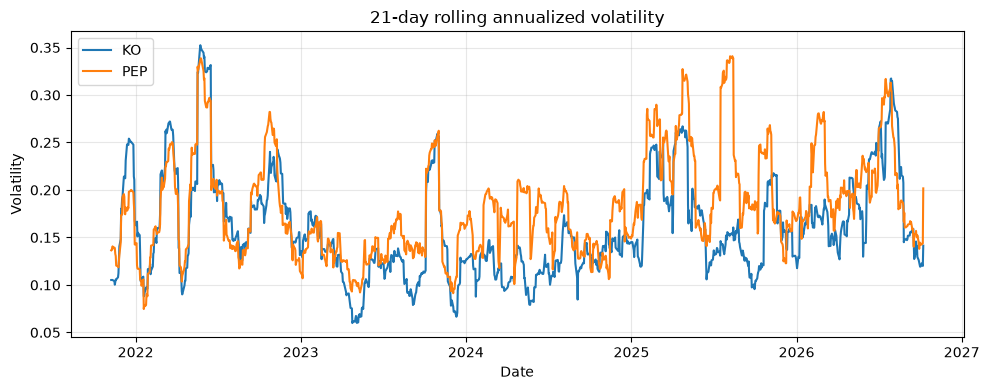

In [173]:
rolling_vol = baseline_returns.rolling(21).std() * np.sqrt(252)

plt.figure(figsize=(10, 4))
plt.plot(rolling_vol.index, rolling_vol["KO"], label="KO")
plt.plot(rolling_vol.index, rolling_vol["PEP"], label="PEP")

plt.title("21-day rolling annualized volatility")
plt.ylabel("Volatility")
plt.xlabel("Date")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


These diagnostics are used to understand the limitations of the random walk, not to introduce a more complex volatility model. I keep constant volatility as a simplifying assumption consistent with the framework used in class.


### Correlation between KO and PEP

The independent random walk assumes that KO and PEP receive unrelated shocks. I keep this model as a benchmark, but I also examine the historical correlation because the two stocks may move together on the same day.


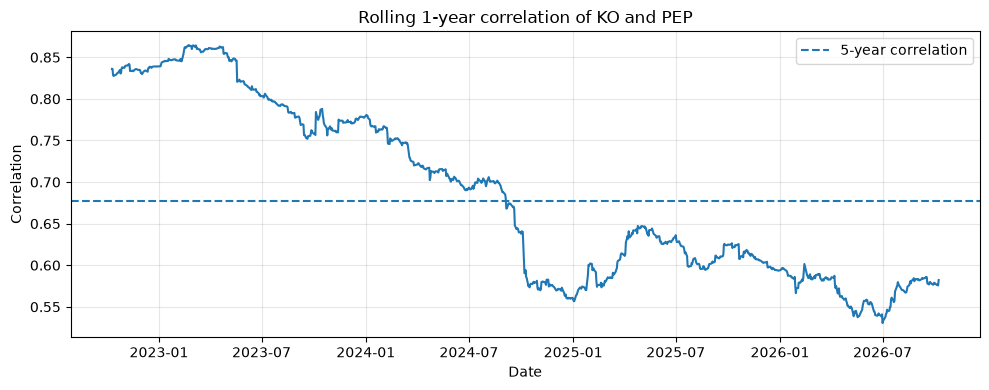

In [174]:
rolling_corr = baseline_returns["KO"].rolling(252).corr(
    baseline_returns["PEP"]
)

plt.figure(figsize=(10, 4))
plt.plot(rolling_corr.index, rolling_corr)
plt.axhline(rho, linestyle="--", label="5-year correlation")

plt.title("Rolling 1-year correlation of KO and PEP")
plt.ylabel("Correlation")
plt.xlabel("Date")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [175]:
rolling_corr_clean = rolling_corr.dropna()

print("5-year correlation:", round(rho, 3))
print("Average rolling 1-year correlation:", round(rolling_corr_clean.mean(), 3))
print("Minimum rolling 1-year correlation:", round(rolling_corr_clean.min(), 3))
print("Maximum rolling 1-year correlation:", round(rolling_corr_clean.max(), 3))


5-year correlation: 0.677
Average rolling 1-year correlation: 0.683
Minimum rolling 1-year correlation: 0.531
Maximum rolling 1-year correlation: 0.864


A stable positive correlation would support using a correlated random walk as the main stock-price model, while the independent model remains a useful benchmark. I keep correlation constant during each 60-day simulation as another simplifying assumption.


## 3. Relative performance and mean reversion

Correlation does not imply mean reversion. KO and PEP can move together while their relative price continues to drift apart.

Because the trade uses equal dollar positions rather than an equal number of shares, the raw price difference $P^{PEP}-P^{KO}$ does not directly represent the trade P&L. I first look at the stocks normalized to 1.


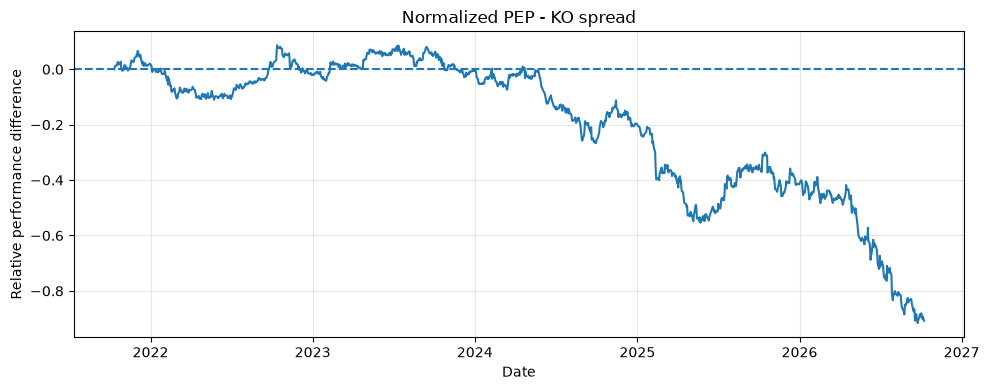

In [176]:
normalized_baseline = baseline_prices / baseline_prices.iloc[0]

normalized_spread = (
    normalized_baseline["PEP"]
    - normalized_baseline["KO"]
)

plt.figure(figsize=(10, 4))
plt.plot(normalized_spread.index, normalized_spread)
plt.axhline(0, linestyle="--")

plt.title("Normalized PEP - KO spread")
plt.ylabel("Relative performance difference")
plt.xlabel("Date")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


To measure the relative price relationship independently of nominal stock levels, we use the log price ratio $X_t = \log(P^{PEP}_t) - \log(P^{KO}_t)$. 

Unlike raw price differences ($P^{PEP} - P^{KO}$), which expand as stock prices grow over time, the log ratio captures percentage differences. Furthermore, multiplying prices by a constant scale factor translates into a simple vertical shift in $X_t$, leaving its variance, autocorrelation, and mean-reverting properties (stationarity) completely intact.


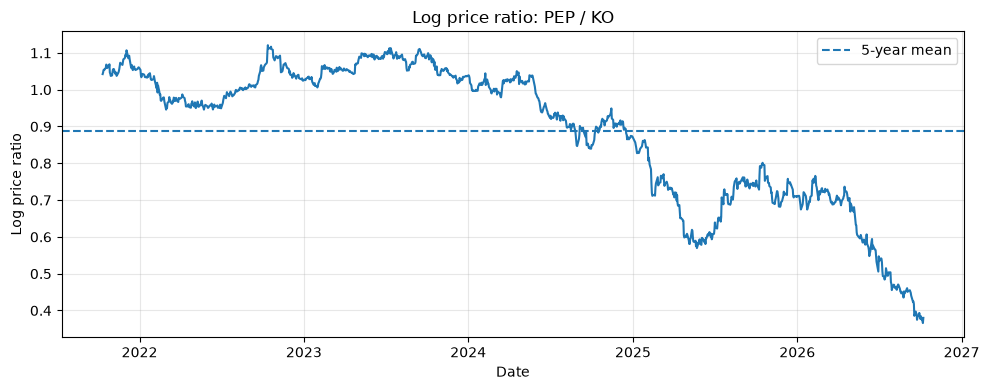

In [177]:
log_ratio = (
    np.log(baseline_prices["PEP"])
    - np.log(baseline_prices["KO"])
)

plt.figure(figsize=(10, 4))
plt.plot(log_ratio.index, log_ratio)
plt.axhline(log_ratio.mean(), linestyle="--", label="5-year mean")

plt.title("Log price ratio: PEP / KO")
plt.ylabel("Log price ratio")
plt.xlabel("Date")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Mean-reversion check

An OU process assumes that the variable tends to return toward a stable long-run level. I use the Augmented Dickey-Fuller test as a simple supporting check on the log price ratio.

The null hypothesis is that the series has a unit root. A low p-value would provide evidence in favor of stationarity; a high p-value would make a fixed-mean OU assumption harder to justify.


In [178]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(log_ratio.dropna())

print("ADF statistic:", round(adf_result[0], 3))
print("p-value:", round(adf_result[1], 4))

print("\nCritical values:")
for level, value in adf_result[4].items():
    print(f"{level}: {value:.3f}")


ADF statistic: 1.057
p-value: 0.9948

Critical values:
1%: -3.436
5%: -2.864
10%: -2.568


### Distribution of daily returns

The Monte Carlo models use Gaussian daily shocks. I therefore check whether the historical log returns are reasonably consistent with this approximation.

The distributions do not need to be perfectly normal. In particular, financial returns can have heavier tails. I retain Gaussian shocks as a simplifying assumption for the random walk models.

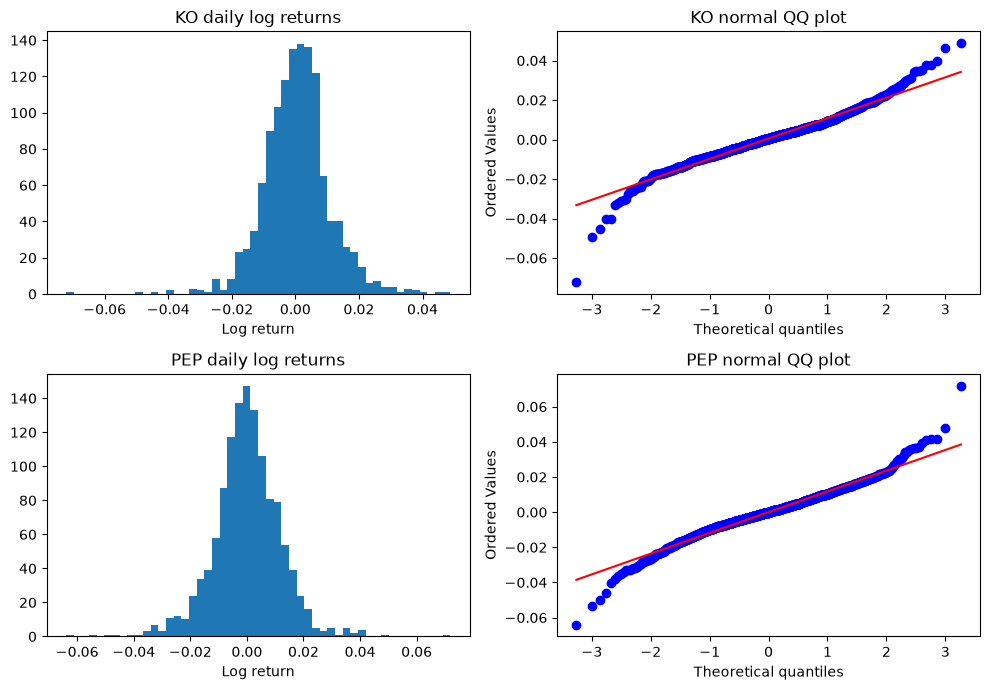

In [179]:
from scipy import stats

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes[0, 0].hist(
    baseline_returns["KO"].dropna(),
    bins=50
)
axes[0, 0].set_title("KO daily log returns")
axes[0, 0].set_xlabel("Log return")

stats.probplot(
    baseline_returns["KO"].dropna(),
    dist="norm",
    plot=axes[0, 1]
)
axes[0, 1].set_title("KO normal QQ plot")

axes[1, 0].hist(
    baseline_returns["PEP"].dropna(),
    bins=50
)
axes[1, 0].set_title("PEP daily log returns")
axes[1, 0].set_xlabel("Log return")

stats.probplot(
    baseline_returns["PEP"].dropna(),
    dist="norm",
    plot=axes[1, 1]
)
axes[1, 1].set_title("PEP normal QQ plot")

plt.tight_layout()
plt.show()

### Main conclusions from the historical data

- **Parameter sensitivity:** Volatility and correlation are relatively stable across the 2, 5, and 10-year lookback windows, while estimated drift is more sensitive to the chosen sample period, particularly for PEP.

- **Random walk assumptions:** Daily return autocorrelation is close to zero for both stocks, which supports a random walk as a simple approximation. Volatility is not constant through time, but I keep constant volatility as a simplifying assumption over the 60-day simulation horizon.

- **Return correlation:** KO and PEP returns are strongly positively correlated. The 5-year estimate is $\rho = 0.677$, and the rolling one-year correlation remains positive throughout the sample.

  For a long PEP / short KO position, positive correlation reduces the variance of relative returns:

$$
\text{Var}(r_{\text{PEP}} - r_{\text{KO}})
=
\sigma_{\text{PEP}}^2
+
\sigma_{\text{KO}}^2
-
2\rho\sigma_{\text{PEP}}\sigma_{\text{KO}}.
$$

  This is important because the trade is mainly exposed to the relative performance of the two stocks rather than to movements that affect both in the same direction. However, the historical correlation is not constant, so a breakdown in this relationship remains a source of risk.

- **Mean reversion:** The ADF test on the log price ratio

$$
X_t =
\log(P^{\text{PEP}}_t)
-
\log(P^{\text{KO}}_t)
$$

gives a p-value of **0.995**. I therefore cannot reject the presence of a unit root. Together with the historical plots, this provides little evidence of a stable mean-reverting relationship over the full sample.

Correlation and mean reversion should therefore be treated separately: KO and PEP tend to move together, but this does not imply that their relative price always returns to a fixed long-run mean.

### Trade setup

On October 9th, 2026, at the market close, the trade is:

- Long USD $100,000 of PEP.
- Short USD $100,000 of KO.

The short-sale proceeds are used to finance the PEP position, while the original USD $100,000 cash remains in the bank earning 5% per year.

The trade is dollar-neutral at inception. Its P&L depends mainly on whether PEP outperforms or underperforms KO after the entry date.

Using normalized prices,

$$
I_{\text{PEP},t}
=
\frac{P_{\text{PEP},t}}{P_{\text{PEP},0}},
\qquad
I_{\text{KO},t}
=
\frac{P_{\text{KO},t}}{P_{\text{KO},0}},
$$

the approximate pairs-trade P&L is

$$
\text{P\&L}_t
=
100{,}000
\left(
I_{\text{PEP},t}
-
I_{\text{KO},t}
\right).
$$

Entry and exit rules will be considered after comparing the simulated behavior of the different models.

### Modeling approach

The 5-year historical estimates of drift, volatility, and correlation are used as constant parameters over the 60-day simulation horizon. This is a simplifying assumption: these parameters can change through time, but keeping them constant gives a transparent model that is consistent with the random walk framework used in class.

I compare three specifications:

1. **Independent random walks — benchmark**

   KO and PEP have their own estimated drift and volatility, but their daily shocks are assumed to be independent. This model is useful as a benchmark because it shows what happens when the historical relationship between the two stocks is ignored.

2. **Correlated random walks — main model**

   The marginal behavior of each stock is the same as in the independent model, but the daily shocks are correlated using the historical estimate $\rho = 0.677$.

   This is the main specification because the positive return correlation is clearly supported by the historical data, while it does not require assuming that the relative price is mean reverting.

3. **Ornstein-Uhlenbeck process — alternative model**

   The OU model assumes that the relative price is pulled toward a long-run level. This is economically relevant for a traditional pairs-trading strategy, but the historical data do not provide strong evidence that this assumption holds for KO and PEP over the full sample.

   The ADF test provides no evidence that the relative price is stationary around a fixed long-run level. This does not rule out every possible form of local or trend-adjusted mean reversion, so I retain OU as an alternative scenario rather than as the baseline model.

The 60 trading days after the entry date are not used for parameter estimation or model selection. They are the future horizon over which the P&L distribution is simulated.

### Operational assumptions

To keep the simulation focused on the stochastic behavior of the pair, I make the following simplifying assumptions:

- Fractional shares can be traded, so exactly USD $100,000 can be invested in each position.
- There are no transaction costs, bid-ask spreads, market impact, taxes, or short-borrow fees.
- The short-sale proceeds can be fully used to finance the PEP position.
- The original USD $100,000 cash remains in the bank and earns 5% per year.
- There are no margin calls or constraints on maintaining the short position.
- Historical adjusted prices are used to estimate returns, so dividends are not added separately.
- Drift, volatility, and correlation are assumed constant over the 60-day simulation horizon.

## 4. Monte Carlo simulation

I simulate 1,000,000 daily paths over 60 trading days.

Daily log returns are modeled as:

$$
r_{i,t} = \mu_i + \sigma_i Z_{i,t},
$$

where $\mu_i$ and $\sigma_i$ are the daily mean and volatility estimated from the 5-year historical window.

The normalized price index evolves as:

$$
I_{i,t+1} = I_{i,t}e^{r_{i,t}},
\qquad I_{i,0}=1.
$$

Because $\mu_i$ is estimated directly from historical log returns, no additional $-\frac{1}{2}\sigma^2$ adjustment is applied.

The first model assumes independent shocks. The second keeps the same marginal distributions but introduces the historical KO-PEP correlation.

In [180]:
mu_daily = baseline_returns[["KO", "PEP"]].mean()
sigma_daily = baseline_returns[["KO", "PEP"]].std()
rho = baseline_returns["KO"].corr(baseline_returns["PEP"])

print("Daily mean log returns:")
display(mu_daily)

print("Daily volatility:")
display(sigma_daily)

print("Correlation:", round(rho, 3))

Daily mean log returns:


Ticker
KO     0.000502
PEP   -0.000027
dtype: float64

Daily volatility:


Ticker
KO     0.010514
PEP    0.011962
dtype: float64

Correlation: 0.677


In [181]:
valuation_steps = len(
    pd.bdate_range(
        start=pd.Timestamp(entry_date) + pd.offsets.BDay(1),
        end=pd.Timestamp(valuation_date)
    )
)

print("Trading days from entry to valuation:", valuation_steps)

Trading days from entry to valuation: 5


### 4.1 Independent random walks

As a benchmark, KO and PEP are first simulated with independent daily shocks:

$$
\text{Corr}(Z_{\text{KO},t},Z_{\text{PEP},t})=0.
$$

This ignores the strong positive correlation observed historically, so it is not my preferred specification. It provides a useful benchmark for measuring the effect of correlation on the risk of the pairs trade.

In [182]:
def simulate_pair(correlation, seed=42):

    rng_sim = np.random.default_rng(seed)

    ko_index = np.ones(n_paths)
    pep_index = np.ones(n_paths)

    # Keep only a small number of complete paths for plotting
    sample_paths = 50
    ko_sample = np.ones((n_days + 1, sample_paths))
    pep_sample = np.ones((n_days + 1, sample_paths))

    corr_matrix = np.array([
        [1.0, correlation],
        [correlation, 1.0]
    ])

    L = np.linalg.cholesky(corr_matrix)

    pnl_valuation = None

    for day in range(1, n_days + 1):

        z = rng_sim.standard_normal((2, n_paths))

        # Apply the required correlation
        shocks = L @ z

        r_ko = (
            mu_daily["KO"]
            + sigma_daily["KO"] * shocks[0]
        )

        r_pep = (
            mu_daily["PEP"]
            + sigma_daily["PEP"] * shocks[1]
        )

        ko_index *= np.exp(r_ko)
        pep_index *= np.exp(r_pep)

        ko_sample[day] = ko_index[:sample_paths]
        pep_sample[day] = pep_index[:sample_paths]

        if day == valuation_steps:
            pnl_valuation = position_size * (
                pep_index - ko_index
            )

    pnl_60 = position_size * (
        pep_index - ko_index
    )

    return pnl_valuation, pnl_60, ko_sample, pep_sample

In [183]:
pnl_ind_5, pnl_ind_60, ko_ind_sample, pep_ind_sample = (
    simulate_pair(correlation=0.0, seed=42)
)

In [184]:
ind_results = pd.Series({
    "Expected pair P&L": pnl_ind_5.mean(),
    "5th percentile": np.percentile(pnl_ind_5, 5),
    "95th percentile": np.percentile(pnl_ind_5, 95)
})

### 4.2 Correlated random walks

The main specification allows KO and PEP to receive correlated shocks.

The historical 5-year correlation is used:

$$
\rho = 0.677.
$$

The individual drift and volatility assumptions remain unchanged. Only the dependence between the two daily shocks is introduced through a Cholesky decomposition.

In [185]:
pnl_corr_5, pnl_corr_60, ko_corr_sample, pep_corr_sample = (
    simulate_pair(correlation=rho, seed=42)
)

In [186]:
corr_results = pd.Series({
    "Expected pair P&L": pnl_corr_5.mean(),
    "5th percentile": np.percentile(pnl_corr_5, 5),
    "95th percentile": np.percentile(pnl_corr_5, 95)
})

comparison_5d = pd.DataFrame({
    "Independent": ind_results,
    "Correlated": corr_results
})

display(comparison_5d.round(2))

,Independent,Correlated
Expected pair P&L,-258.89,-257.62
5th percentile,-6113.42,-3601.23
95th percentile,5616.27,3112.86


### Cash account

The original USD $100,000 remains in the bank and earns 5% per year.

I assume daily compounding over 252 trading days:

$$
C_t =
100{,}000
\left(1+\frac{0.05}{252}\right)^t.
$$

The total portfolio value is therefore the cash account plus the P&L of the long-short position.

In [187]:
def cash_value(days):
    return initial_cash * (1 + cash_rate / 252) ** days


cash_5 = cash_value(valuation_steps)
cash_60 = cash_value(n_days)

print("Cash value on valuation date:", round(cash_5, 2))
print("Cash value after 60 trading days:", round(cash_60, 2))

Cash value on valuation date: 100099.25
Cash value after 60 trading days: 101197.47


In [188]:
total_value_corr_5 = cash_5 + pnl_corr_5

total_results_5 = pd.Series({
    "Expected portfolio value": total_value_corr_5.mean(),
    "Expected total P&L": total_value_corr_5.mean() - initial_cash,
    "5th percentile total P&L": (
        np.percentile(total_value_corr_5, 5) - initial_cash
    ),
    "95th percentile total P&L": (
        np.percentile(total_value_corr_5, 95) - initial_cash
    )
})

display(total_results_5.round(2))

Expected portfolio value     99841.62
Expected total P&L            -158.38
5th percentile total P&L     -3501.98
95th percentile total P&L     3212.10
dtype: float64

### Short-horizon simulation results

The independent and correlated models produce almost the same expected P&L because correlation changes the joint behavior of KO and PEP, but not their individual expected returns.

The main difference is the dispersion of outcomes. Introducing the historical positive correlation makes the P&L distribution substantially narrower because common movements in KO and PEP tend to offset each other in the long-short position.

Under the correlated model, the expected pair P&L on October 16th is approximately **-$258**. After including interest earned on the USD $100,000 cash account, the expected total P&L is approximately **-$158**, with a 5th percentile of approximately **-$3,502** and a 95th percentile of approximately **$3,212**.

The slightly negative expected P&L is mainly driven by the historical drift estimates. Since drift was the parameter most sensitive to the calibration window, this point estimate should be interpreted with caution.

In [189]:
ind_results_60 = pd.Series({
    "Expected pair P&L": pnl_ind_60.mean(),
    "5th percentile": np.percentile(pnl_ind_60, 5),
    "95th percentile": np.percentile(pnl_ind_60, 95)
})

corr_results_60 = pd.Series({
    "Expected pair P&L": pnl_corr_60.mean(),
    "5th percentile": np.percentile(pnl_corr_60, 5),
    "95th percentile": np.percentile(pnl_corr_60, 95)
})

comparison_60d = pd.DataFrame({
    "Independent": ind_results_60,
    "Correlated": corr_results_60
})

display(comparison_60d.round(2))

,Independent,Correlated
Expected pair P&L,-3121.50,-3121.82
5th percentile,-23666.29,-14789.31
95th percentile,17647.97,8828.28


In [190]:
total_value_corr_60 = cash_60 + pnl_corr_60

total_results_60 = pd.Series({
    "Expected portfolio value": total_value_corr_60.mean(),
    "Expected total P&L": total_value_corr_60.mean() - initial_cash,
    "5th percentile total P&L": (
        np.percentile(total_value_corr_60, 5) - initial_cash
    ),
    "95th percentile total P&L": (
        np.percentile(total_value_corr_60, 95) - initial_cash
    )
})

display(total_results_60.round(2))

Expected portfolio value     98075.66
Expected total P&L           -1924.34
5th percentile total P&L    -13591.84
95th percentile total P&L    10025.75
dtype: float64

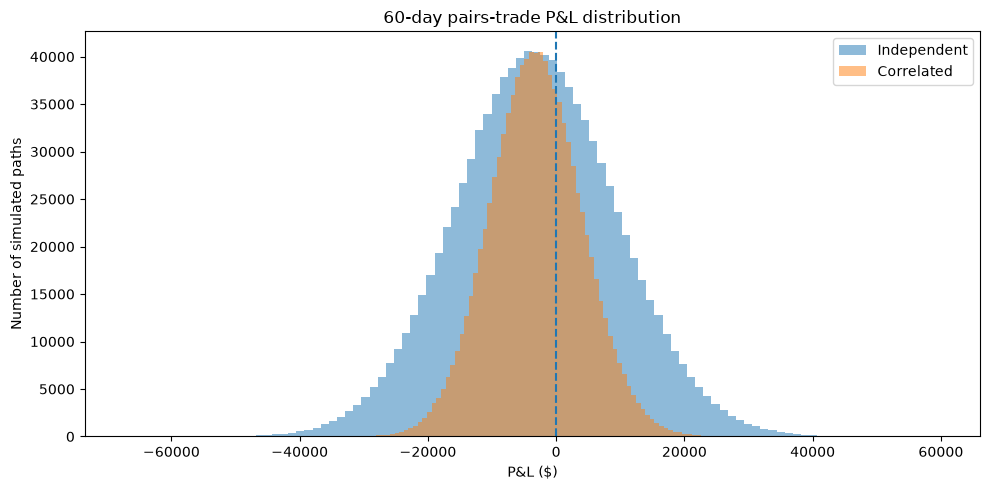

In [191]:
plt.figure(figsize=(10, 5))

plt.hist(
    pnl_ind_60,
    bins=100,
    alpha=0.5,
    label="Independent"
)

plt.hist(
    pnl_corr_60,
    bins=100,
    alpha=0.5,
    label="Correlated"
)

plt.axvline(0, linestyle="--")

plt.title("60-day pairs-trade P&L distribution")
plt.xlabel("P&L ($)")
plt.ylabel("Number of simulated paths")
plt.legend()
plt.tight_layout()
plt.show()

In [192]:
def simulate_correlated_fan_chart(correlation, seed=42, sample_paths=100):

    rng_fan = np.random.default_rng(seed)

    ko_index = np.ones(n_paths)
    pep_index = np.ones(n_paths)

    corr_matrix = np.array([
        [1.0, correlation],
        [correlation, 1.0]
    ])

    L = np.linalg.cholesky(corr_matrix)

    # Statistics calculated using all 1,000,000 paths
    mean_pnl = np.zeros(n_days + 1)
    p5_pnl = np.zeros(n_days + 1)
    p95_pnl = np.zeros(n_days + 1)

    # Only a small subset is stored for plotting individual paths
    sample_pnl = np.zeros((n_days + 1, sample_paths))

    for day in range(1, n_days + 1):

        z = rng_fan.standard_normal((2, n_paths))
        shocks = L @ z

        r_ko = (
            mu_daily["KO"]
            + sigma_daily["KO"] * shocks[0]
        )

        r_pep = (
            mu_daily["PEP"]
            + sigma_daily["PEP"] * shocks[1]
        )

        ko_index *= np.exp(r_ko)
        pep_index *= np.exp(r_pep)

        pnl = position_size * (
            pep_index - ko_index
        )

        mean_pnl[day] = pnl.mean()
        p5_pnl[day] = np.percentile(pnl, 5)
        p95_pnl[day] = np.percentile(pnl, 95)

        sample_pnl[day] = pnl[:sample_paths]

    return mean_pnl, p5_pnl, p95_pnl, sample_pnl

In [193]:
mean_pnl_path, p5_pnl_path, p95_pnl_path, sample_pnl_paths = (
    simulate_correlated_fan_chart(
        correlation=rho,
        seed=42,
        sample_paths=100
    )
)

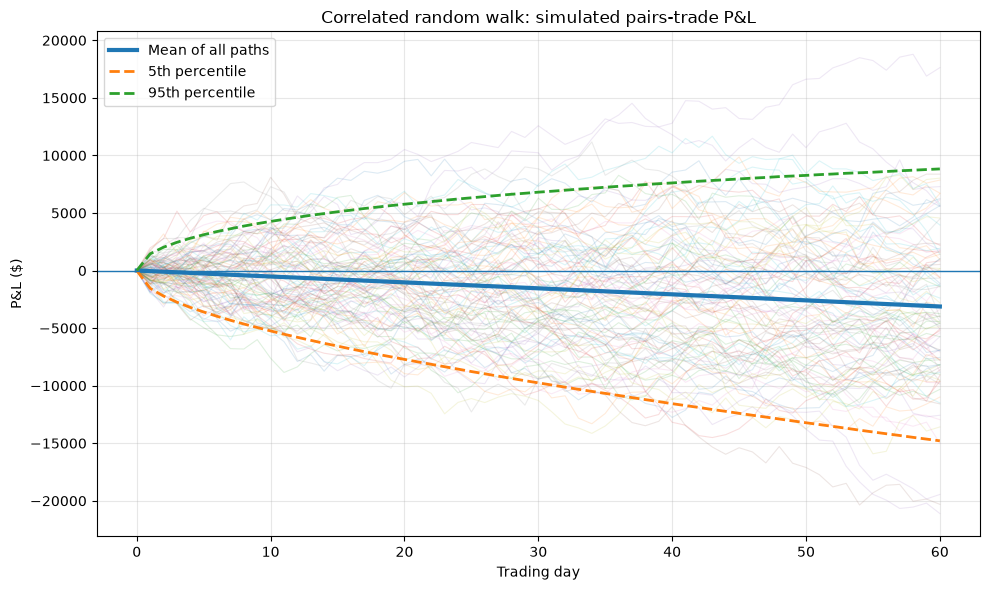

In [194]:
days = np.arange(n_days + 1)

plt.figure(figsize=(10, 6))

# Plot only 100 sample paths
for i in range(sample_pnl_paths.shape[1]):
    plt.plot(
        days,
        sample_pnl_paths[:, i],
        alpha=0.15,
        linewidth=0.8
    )

# Statistics based on all 1,000,000 paths
plt.plot(
    days,
    mean_pnl_path,
    linewidth=3,
    label="Mean of all paths"
)

plt.plot(
    days,
    p5_pnl_path,
    linestyle="--",
    linewidth=2,
    label="5th percentile"
)

plt.plot(
    days,
    p95_pnl_path,
    linestyle="--",
    linewidth=2,
    label="95th percentile"
)

plt.axhline(0, linewidth=1)

plt.title("Correlated random walk: simulated pairs-trade P&L")
plt.xlabel("Trading day")
plt.ylabel("P&L ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Entry and exit rule

The full-sample log price ratio is not stationary, so I do not use the 5-year historical mean as a fixed trading anchor.

Instead, I define a local relative-value signal using the previous 252 trading days:

$$
X_t = \log\left(\frac{P^{PEP}_t}{P^{KO}_t}\right),
$$

and

$$
z_t = \frac{X_t-\bar X}{s_X},
$$

where $\bar X$ and $s_X$ are estimated using only the 252 trading days before the entry date.

Since the assigned trade is long PEP and short KO, the relevant entry signal occurs when PEP is relatively cheap:

$$
z_t \leq -2.
$$

I exit when the relative price returns to its local mean:

$$
z_t = 0.
$$

This is a relative-value trading rule rather than an assumption of permanent long-run mean reversion. The reference mean and standard deviation are fixed at entry so that the exit level is defined in advance.

In [195]:
signal_window = 252

log_ratio = np.log(
    adj_close["PEP"] / adj_close["KO"]
)

# Only information strictly before the entry date
signal_history = (
    log_ratio[log_ratio.index < entry]
    .tail(signal_window)
)

local_mean = signal_history.mean()
local_std = signal_history.std()

# Observed relative price at the entry close
x_entry = log_ratio.loc[entry]

z_entry = (
    (x_entry - local_mean)
    / local_std
)

print("Local mean log-ratio:", round(local_mean, 4))
print("Local standard deviation:", round(local_std, 4))
print("Entry log-ratio:", round(x_entry, 4))
print("Entry z-score:", round(z_entry, 2))

Local mean log-ratio: 0.6248
Local standard deviation: 0.1215
Entry log-ratio: 0.3581
Entry z-score: -2.2


In [196]:
entry_z_threshold = -2.0
exit_z_threshold = 0.0

x_entry_threshold = (
    local_mean
    + entry_z_threshold * local_std
)

x_exit_threshold = (
    local_mean
    + exit_z_threshold * local_std
)

entry_ratio_threshold = np.exp(x_entry_threshold)
exit_ratio_threshold = np.exp(x_exit_threshold)

print(
    "Entry PEP/KO ratio threshold:",
    round(entry_ratio_threshold, 3)
)

print(
    "Exit PEP/KO ratio threshold:",
    round(exit_ratio_threshold, 3)
)

Entry PEP/KO ratio threshold: 1.465
Exit PEP/KO ratio threshold: 1.868


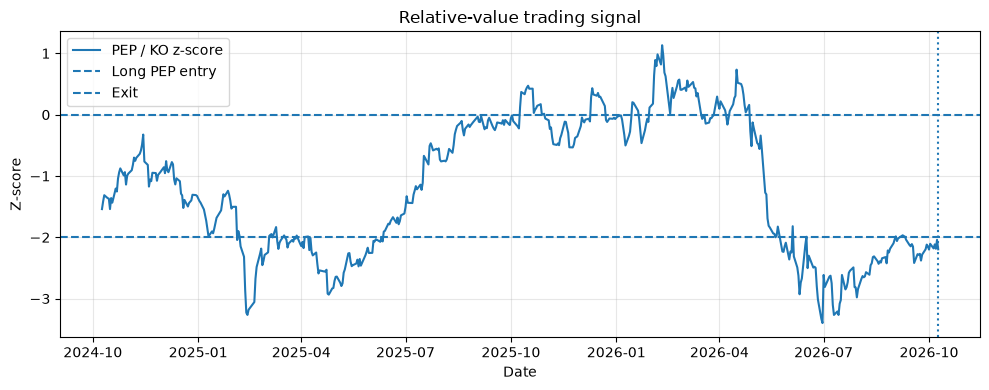

In [197]:
rolling_mean = (
    log_ratio
    .shift(1)
    .rolling(signal_window)
    .mean()
)

rolling_std = (
    log_ratio
    .shift(1)
    .rolling(signal_window)
    .std()
)

z_score = (
    (log_ratio - rolling_mean)
    / rolling_std
)

plot_start = entry - pd.DateOffset(years=2)

plt.figure(figsize=(10, 4))

plt.plot(
    z_score.loc[plot_start:entry].index,
    z_score.loc[plot_start:entry],
    label="PEP / KO z-score"
)

plt.axhline(-2, linestyle="--", label="Long PEP entry")
plt.axhline(0, linestyle="--", label="Exit")
plt.axvline(entry, linestyle=":")

plt.title("Relative-value trading signal")
plt.ylabel("Z-score")
plt.xlabel("Date")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [198]:
# Actual quoted prices on the entry date
ko_entry_price = close.loc[entry, "KO"]
pep_entry_price = close.loc[entry, "PEP"]

# Adjustment factors on the entry date
ko_adj_factor = adj_close.loc[entry, "KO"] / ko_entry_price
pep_adj_factor = adj_close.loc[entry, "PEP"] / pep_entry_price

# Convert adjusted-price ratio thresholds into quoted-price ratios
adjustment_ratio = pep_adj_factor / ko_adj_factor

entry_close_ratio = entry_ratio_threshold / adjustment_ratio
exit_close_ratio = exit_ratio_threshold / adjustment_ratio

# Equivalent quoted prices, conditional on KO remaining at its entry price
entry_pep_price = entry_close_ratio * ko_entry_price
exit_pep_price = exit_close_ratio * ko_entry_price

entry_difference = entry_pep_price - ko_entry_price
exit_difference = exit_pep_price - ko_entry_price

actual_close_ratio = pep_entry_price / ko_entry_price
actual_difference = pep_entry_price - ko_entry_price

print("KO price on entry date:", round(ko_entry_price, 2))
print("PEP price on entry date:", round(pep_entry_price, 2))

print("\nActual quoted PEP/KO ratio:", round(actual_close_ratio, 3))
print("Actual PEP - KO difference:", round(actual_difference, 2))

print("\nEntry adjusted-ratio threshold:", round(entry_ratio_threshold, 3))
print("Equivalent quoted entry differential ($):", round(entry_difference, 2))

print("\nExit adjusted-ratio target:", round(exit_ratio_threshold, 3))
print("Equivalent quoted exit differential ($):", round(exit_difference, 2))

KO price on entry date: 88.05
PEP price on entry date: 125.97

Actual quoted PEP/KO ratio: 1.431
Actual PEP - KO difference: 37.92

Entry adjusted-ratio threshold: 1.465
Equivalent quoted entry differential ($): 40.95

Exit adjusted-ratio target: 1.868
Equivalent quoted exit differential ($): 76.42


### Entry and exit levels

On October 9th, the PEP/KO ratio is **1.431** and its z-score is **-2.19**. This is below the entry threshold of -2, so the assigned long PEP / short KO trade is consistent with the relative-value signal.

The entry rule is:

$$
z_t \leq -2
\qquad\Longleftrightarrow\qquad
\frac{PEP_t}{KO_t} \leq 1.465.
$$

With KO at $88.05, this corresponds to a PEP price of approximately $128.99, or a PEP-KO price difference of approximately **$40.94**. The actual difference on October 9th is **$37.92**, so the entry condition is satisfied.

The convergence target is:

$$
z_t = 0
\qquad\Longleftrightarrow\qquad
\frac{PEP_t}{KO_t} \approx 1.883.
$$

If KO remained at $88.05, this would correspond to a PEP-KO difference of approximately **$77.71**.

The ratio and z-score are the actual trading rules. The dollar differentials are only equivalent levels conditional on KO remaining at its entry price.

Since the full-sample relative price is non-stationary, the exit level should be viewed as a local relative-value target rather than a guaranteed equilibrium.

## 6. Mean-reverting alternative: Ornstein-Uhlenbeck

The full historical sample does not support stable mean reversion, so I do not use OU as the main model.

Instead, I consider OU as a local mean-reversion scenario based on the 252 trading days before entry. This is consistent with the relative-value signal used for the entry and exit rule.

The discrete process is:

$$
X_{t+1}
=
\theta
+
\phi(X_t-\theta)
+
\varepsilon_t,
$$

where $X_t=\log(PEP_t/KO_t)$, $\theta$ is the local mean, and $0<\phi<1$ controls the speed of mean reversion.

In [199]:
ou_history = log_ratio[
    log_ratio.index < entry
].tail(252)

theta_ou = ou_history.mean()
phi_ou = ou_history.autocorr(lag=1)

ou_std = ou_history.std()

# Innovation volatility consistent with the historical variance
sigma_ou = ou_std * np.sqrt(1 - phi_ou**2)

x0_ou = log_ratio.loc[entry]

print("OU long-run mean:", round(theta_ou, 4))
print("OU persistence (phi):", round(phi_ou, 4))
print("OU daily innovation volatility:", round(sigma_ou, 4))
print("Initial log-ratio:", round(x0_ou, 4))

OU long-run mean: 0.6248
OU persistence (phi): 0.9954
OU daily innovation volatility: 0.0116
Initial log-ratio: 0.3581


In [200]:
if 0 < phi_ou < 1:
    half_life = np.log(0.5) / np.log(phi_ou)

    print(
        "Estimated mean-reversion half-life:",
        round(half_life, 1),
        "trading days"
    )
else:
    print(
        "The estimated persistence is not consistent "
        "with a mean-reverting OU process."
    )

Estimated mean-reversion half-life: 150.4 trading days


In [201]:
def simulate_ou_pair(seed=42):

    rng_ou = np.random.default_rng(seed)

    ko_index = np.ones(n_paths)
    x = np.full(n_paths, x0_ou)

    pnl_valuation = None

    for day in range(1, n_days + 1):

        z_ko = rng_ou.standard_normal(n_paths)
        z_x = rng_ou.standard_normal(n_paths)

        # KO follows the same random walk assumption
        r_ko = (
            mu_daily["KO"]
            + sigma_daily["KO"] * z_ko
        )

        ko_index *= np.exp(r_ko)

        # Relative price follows the local OU process
        x = (
            theta_ou
            + phi_ou * (x - theta_ou)
            + sigma_ou * z_x
        )

        pep_index = (
            ko_index
            * np.exp(x - x0_ou)
        )

        if day == valuation_steps:
            pnl_ou_5 = position_size * (
                pep_index - ko_index
            )

    pnl_ou_60 = position_size * (
        pep_index - ko_index
    )

    return pnl_ou_5, pnl_ou_60

In [202]:
pnl_ou_5, pnl_ou_60 = simulate_ou_pair(seed=42)

In [203]:
ou_results_5 = pd.Series({
    "Expected pair P&L": pnl_ou_5.mean(),
    "5th percentile": np.percentile(pnl_ou_5, 5),
    "95th percentile": np.percentile(pnl_ou_5, 95)
})

model_comparison_5d = pd.DataFrame({
    "Independent RW": ind_results,
    "Correlated RW": corr_results,
    "Local OU": ou_results_5
})

display(model_comparison_5d.round(2))

,Independent RW,Correlated RW,Local OU
Expected pair P&L,-258.89,-257.62,643.79
5th percentile,-6113.42,-3601.23,-3573.15
95th percentile,5616.27,3112.86,4974.97


In [204]:
ou_results_60 = pd.Series({
    "Expected pair P&L": pnl_ou_60.mean(),
    "5th percentile": np.percentile(pnl_ou_60, 5),
    "95th percentile": np.percentile(pnl_ou_60, 95)
})

model_comparison_60d = pd.DataFrame({
    "Independent RW": ind_results_60,
    "Correlated RW": corr_results_60,
    "Local OU": ou_results_60
})

display(model_comparison_60d.round(2))

,Independent RW,Correlated RW,Local OU
Expected pair P&L,-3121.50,-3121.82,7242.31
5th percentile,-23666.29,-14789.31,-6527.03
95th percentile,17647.97,8828.28,22352.75


### Comparison of model assumptions

The OU model produces a substantially more positive expected P&L than the random walk models.

This result is driven by the mean-reversion assumption. At entry, the PEP/KO log-ratio is well below its estimated local mean, so the OU process pulls the relative price upward. This directly benefits the long PEP / short KO position.

However, the estimated mean reversion is slow, with a half-life of approximately **154 trading days**, which is longer than the 60-day simulation horizon. The model therefore implies only partial convergence during the trade.

More importantly, the full historical sample does not support stable mean reversion. The OU results should therefore be interpreted as a mean-reversion scenario rather than the main forecast.

The correlated random walk remains the baseline model because positive return correlation is clearly supported by the historical data without requiring the stronger assumption that the relative price must return to a fixed mean.

In [205]:
model_total_5d = pd.DataFrame({
    "Independent RW": {
        "Expected total P&L": pnl_ind_5.mean() + cash_5 - initial_cash,
        "5th percentile": np.percentile(pnl_ind_5, 5) + cash_5 - initial_cash,
        "95th percentile": np.percentile(pnl_ind_5, 95) + cash_5 - initial_cash
    },
    "Correlated RW": {
        "Expected total P&L": pnl_corr_5.mean() + cash_5 - initial_cash,
        "5th percentile": np.percentile(pnl_corr_5, 5) + cash_5 - initial_cash,
        "95th percentile": np.percentile(pnl_corr_5, 95) + cash_5 - initial_cash
    },
    "Local OU": {
        "Expected total P&L": pnl_ou_5.mean() + cash_5 - initial_cash,
        "5th percentile": np.percentile(pnl_ou_5, 5) + cash_5 - initial_cash,
        "95th percentile": np.percentile(pnl_ou_5, 95) + cash_5 - initial_cash
    }
})

display(model_total_5d.round(2))

,Independent RW,Correlated RW,Local OU
Expected total P&L,-159.64,-158.38,743.04
5th percentile,-6014.17,-3501.98,-3473.90
95th percentile,5715.51,3212.10,5074.22


In [206]:
model_total_60d = pd.DataFrame({
    "Independent RW": {
        "Expected total P&L": pnl_ind_60.mean() + cash_60 - initial_cash,
        "5th percentile": np.percentile(pnl_ind_60, 5) + cash_60 - initial_cash,
        "95th percentile": np.percentile(pnl_ind_60, 95) + cash_60 - initial_cash
    },
    "Correlated RW": {
        "Expected total P&L": pnl_corr_60.mean() + cash_60 - initial_cash,
        "5th percentile": np.percentile(pnl_corr_60, 5) + cash_60 - initial_cash,
        "95th percentile": np.percentile(pnl_corr_60, 95) + cash_60 - initial_cash
    },
    "Local OU": {
        "Expected total P&L": pnl_ou_60.mean() + cash_60 - initial_cash,
        "5th percentile": np.percentile(pnl_ou_60, 5) + cash_60 - initial_cash,
        "95th percentile": np.percentile(pnl_ou_60, 95) + cash_60 - initial_cash
    }
})

display(model_total_60d.round(2))

,Independent RW,Correlated RW,Local OU
Expected total P&L,-1924.03,-1924.34,8439.78
5th percentile,-22468.82,-13591.84,-5329.55
95th percentile,18845.44,10025.75,23550.22


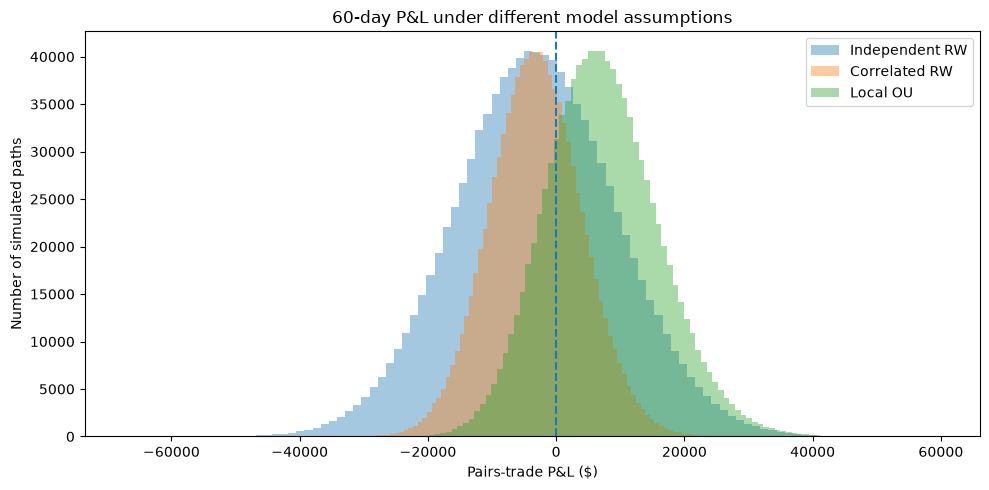

In [207]:
plt.figure(figsize=(10, 5))

plt.hist(
    pnl_ind_60,
    bins=100,
    alpha=0.4,
    label="Independent RW"
)

plt.hist(
    pnl_corr_60,
    bins=100,
    alpha=0.4,
    label="Correlated RW"
)

plt.hist(
    pnl_ou_60,
    bins=100,
    alpha=0.4,
    label="Local OU"
)

plt.axvline(0, linestyle="--")

plt.title("60-day P&L under different model assumptions")
plt.xlabel("Pairs-trade P&L ($)")
plt.ylabel("Number of simulated paths")
plt.legend()
plt.tight_layout()
plt.show()

## Final answer

The **correlated random walk** is my baseline model because the historical data show a persistent positive correlation between KO and PEP returns, while there is little evidence that their relative price is stationary around a fixed long-run level.

For a trade entered on October 9th and valued on October 16th:

- Expected pairs-trade P&L: approximately **-$258**.
- Expected total P&L including interest on cash: approximately **-$158**.
- Expected portfolio value: approximately **$99,842**.
- 5th percentile total P&L: approximately **-$3,502**.
- 95th percentile total P&L: approximately **+$3,212**.

The relative-value entry rule is:

$$
z_t \leq -2.
$$

Using the previous 252 trading days, this corresponds to an adjusted PEP/KO ratio threshold of approximately **1.465**. On October 9th, the observed ratio is approximately **1.431** and the z-score is **-2.19**, so the long PEP / short KO trade satisfies the entry rule.

At the quoted October 9th prices (KO = **$88.05**, PEP = **$125.97**), the actual PEP-KO price differential is **$37.92**. The entry threshold is equivalent to a quoted differential of approximately **$40.95**, conditional on KO remaining at its entry price.

The convergence exit target is:

$$
z_t = 0.
$$

This corresponds to an adjusted PEP/KO ratio of approximately **1.868**. Conditional on KO remaining at $88.05, this is equivalent to a quoted PEP-KO differential of approximately **$76.42**.

The ratio and z-score are the primary trading signals. The dollar differentials are reported as equivalent price levels and depend on the price of KO.

The local OU model produces a much more positive expected P&L (approximately **+$7,242** after 60 trading days) because it explicitly assumes that the relative price moves back toward its local mean. However, the full historical sample provides little evidence of stationarity around a fixed long-run level. I therefore treat the OU model as an alternative mean-reversion scenario rather than the main forecast.